# Practice: K-means on California housing

In-class exercise applying K-means (k = 4) to California housing data, plotting clusters and centroids, and using the elbow method. Also loads the MNIST sample and World Bank 2025 data for exploration.

*Note:* features were not scaled, so variables measured in large units (rooms, population) dominate the distance. Kept as a record of practice.

---
*Coursework: M.Eng. Engineering & Sustainable Technology Management, AI / Machine Learning courses (2025–2026). Originally run in Google Colab.*

In [ ]:
import pandas as pd
data = pd.read_csv("/content/sample_data/california_housing_test.csv")
data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0
...,...,...,...,...,...,...,...,...,...
2995,-119.86,34.42,23.0,1450.0,642.0,1258.0,607.0,1.1790,225000.0
2996,-118.14,34.06,27.0,5257.0,1082.0,3496.0,1036.0,3.3906,237200.0
2997,-119.70,36.30,10.0,956.0,201.0,693.0,220.0,2.2895,62000.0
2998,-117.12,34.10,40.0,96.0,14.0,46.0,14.0,3.2708,162500.0


In [ ]:
from sklearn.cluster import KMeans
kmn = KMeans(n_clusters=4) # creat model : Clustring in this code we supposed 3 clusters
kmn.fit(data[['latitude','housing_median_age','total_rooms','total_bedrooms']]) # fitting data - the input of fitting is a DataFrame with its columns
Clusters = kmn.predict(data[['latitude','housing_median_age','total_rooms','total_bedrooms']])

In [ ]:
data['cluster1']=Clusters # adding a new column
data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,cluster1
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0,1
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0,0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0,1
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0,0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0,0
...,...,...,...,...,...,...,...,...,...,...
2995,-119.86,34.42,23.0,1450.0,642.0,1258.0,607.0,1.1790,225000.0,0
2996,-118.14,34.06,27.0,5257.0,1082.0,3496.0,1036.0,3.3906,237200.0,1
2997,-119.70,36.30,10.0,956.0,201.0,693.0,220.0,2.2895,62000.0,0
2998,-117.12,34.10,40.0,96.0,14.0,46.0,14.0,3.2708,162500.0,0


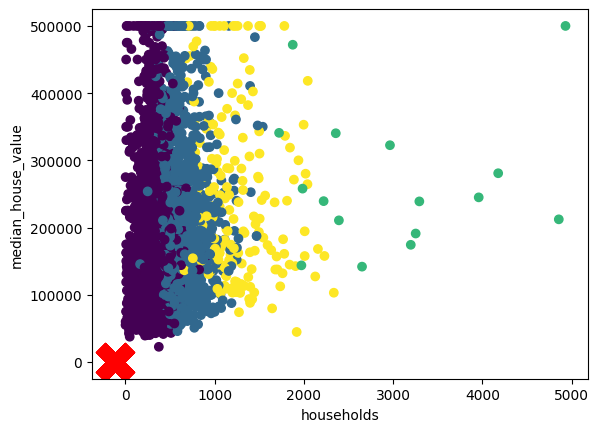

In [ ]:
import matplotlib.pyplot as plt
xs = data['households']
ys = data['median_house_value']

labels = Clusters
centroids = kmn.cluster_centers_ # this is very important function to see the place of center from clustering
plt.scatter(xs, ys, c=labels)
plt.xlabel('households')
plt.ylabel('median_house_value')
plt.scatter(centroids[:,0],centroids[:,2],marker='x', linewidth=10, s=450,c='red')
plt.show()

In [ ]:
centroids

array([[-1.19932958e+02,  3.69667500e+01,  3.00541667e+01,
         1.72102500e+03,  3.85358333e+02,  1.03927917e+03,
         3.50229167e+02,  2.07706708e+00,  6.27895833e+04,
         2.00000000e-01],
       [-1.19988500e+02,  3.55339000e+01,  2.91800000e+01,
         3.19025000e+03,  5.83670000e+02,  1.41788000e+03,
         5.42710000e+02,  5.04820800e+00,  3.29778000e+05,
         6.70000000e-01],
       [-1.19072170e+02,  3.50075472e+01,  2.83490566e+01,
         2.55128302e+03,  5.51287736e+02,  1.54612736e+03,
         5.07919811e+02,  3.45902028e+00,  1.75098113e+05,
         4.85849057e-01],
       [-1.19413684e+02,  3.51302632e+01,  2.98684211e+01,
         3.36773684e+03,  5.62842105e+02,  1.36839474e+03,
         5.24368421e+02,  5.76767368e+00,  4.58847368e+05,
         8.15789474e-01],
       [-1.19836164e+02,  3.55184906e+01,  2.86352201e+01,
         3.22251572e+03,  6.19251572e+02,  1.54198742e+03,
         5.63805031e+02,  4.42923836e+00,  2.48507547e+05,
         6.

In [ ]:
kmn.inertia_

149831112186.09155

In [ ]:
import numpy as np
inertia_list = []
for k in np.arange(1,19): # the structure of loop should be consistent and the next lines should be after for .
    kmn =KMeans(n_clusters = k)
    kmn.fit(data)# only add your data here the rest codes are the same for your dataset
    inertia_list.append(kmn.inertia_)# make a list which we add the caluculation of inertial in each loop to this list
inertia_list

[38393434223112.055,
 12179136477508.893,
 5513572358227.487,
 3080161507495.8525,
 1767766419737.2117,
 1270728818428.8438,
 936030126145.3323,
 781605917289.7273,
 555418039333.2744,
 457085524458.56067,
 399265125827.58026,
 311554048970.65424,
 268651668926.41495,
 223417427218.62006,
 203654883594.2683,
 175787097825.9253,
 162359929599.26303,
 148464301059.1119]

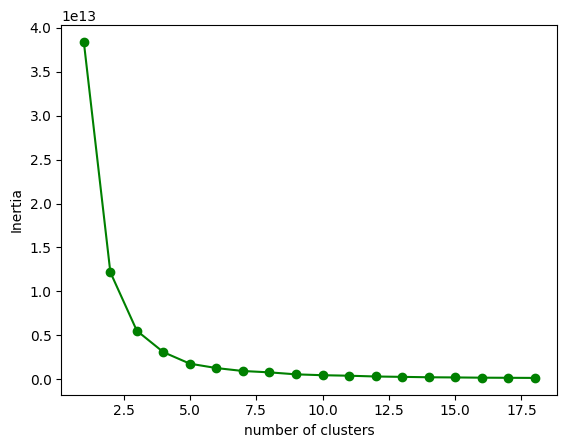

In [ ]:
plt.plot(np.arange(1,19),inertia_list,'o-',c='green')
plt.xlabel('number of clusters')
plt.ylabel('Inertia')
plt.show()

In [ ]:
data2 = pd.read_csv('/content/sample_data/mnist_train_small.csv')

In [ ]:
data2

,6,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,...,0.581,0.582,0.583,0.584,0.585,0.586,0.587,0.588,0.589,0.590
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19995,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19996,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19997,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
new_data = pd.read_csv('/content/world_bank_data_2025.csv')

In [ ]:
new_data

,country_name,country_id,year,Inflation (CPI %),GDP (Current USD),GDP per Capita (Current USD),Unemployment Rate (%),"Interest Rate (Real, %)","Inflation (GDP Deflator, %)",GDP Growth (% Annual),Current Account Balance (% GDP),Government Expense (% of GDP),Government Revenue (% of GDP),Tax Revenue (% of GDP),Gross National Income (USD),Public Debt (% of GDP)
0,Aruba,aw,2010,2.078141,2.453597e+09,24093.140151,NaN,11.666131,-1.223407,-2.733457,-18.752537,NaN,NaN,NaN,2.313385e+09,NaN
1,Aruba,aw,2011,4.316297,2.637859e+09,25712.384302,NaN,4.801974,4.005674,3.369237,-9.877656,NaN,NaN,NaN,2.391841e+09,NaN
2,Aruba,aw,2012,0.627472,2.615208e+09,25119.665545,NaN,8.200875,0.184033,-1.040800,3.473451,NaN,NaN,NaN,2.499118e+09,NaN
3,Aruba,aw,2013,-2.372065,2.727850e+09,25813.576727,NaN,10.709709,-1.995948,6.431483,-11.813206,NaN,NaN,NaN,2.563517e+09,NaN
4,Aruba,aw,2014,0.421441,2.790850e+09,26129.839062,NaN,3.213869,3.958897,-1.586575,-4.658577,NaN,NaN,NaN,2.688102e+09,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3467,Zimbabwe,zw,2021,98.546105,2.724052e+10,1724.387731,9.540,-31.795551,113.294981,8.468017,1.278300,NaN,NaN,NaN,2.662178e+10,NaN
3468,Zimbabwe,zw,2022,104.705171,3.278975e+10,2040.552459,10.087,-36.833393,266.987152,6.139263,0.930064,NaN,NaN,NaN,3.202694e+10,NaN
3469,Zimbabwe,zw,2023,NaN,3.523137e+10,2156.034004,8.759,-73.540441,921.535652,5.336730,0.379995,NaN,NaN,NaN,3.479607e+10,NaN
3470,Zimbabwe,zw,2024,NaN,NaN,NaN,8.554,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
new_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3472 entries, 0 to 3471
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   country_name                     3472 non-null   object 
 1   country_id                       3472 non-null   object 
 2   year                             3472 non-null   int64  
 3   Inflation (CPI %)                2694 non-null   float64
 4   GDP (Current USD)                2933 non-null   float64
 5   GDP per Capita (Current USD)     2938 non-null   float64
 6   Unemployment Rate (%)            2795 non-null   float64
 7   Interest Rate (Real, %)          1735 non-null   float64
 8   Inflation (GDP Deflator, %)      2904 non-null   float64
 9   GDP Growth (% Annual)            2912 non-null   float64
 10  Current Account Balance (% GDP)  2563 non-null   float64
 11  Government Expense (% of GDP)    1820 non-null   float64
 12  Government Revenue (

In [ ]:
data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,cluster1
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0,1
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0,0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0,1
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0,0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0,0
...,...,...,...,...,...,...,...,...,...,...
2995,-119.86,34.42,23.0,1450.0,642.0,1258.0,607.0,1.1790,225000.0,0
2996,-118.14,34.06,27.0,5257.0,1082.0,3496.0,1036.0,3.3906,237200.0,1
2997,-119.70,36.30,10.0,956.0,201.0,693.0,220.0,2.2895,62000.0,0
2998,-117.12,34.10,40.0,96.0,14.0,46.0,14.0,3.2708,162500.0,0


In [ ]:
from sklearn.neighbors import KNeighborsClassifier # First step: creat model
knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski',p=2) # creat model because P= 2 then the method for distance calculation is Euclidiean Method
x = data[['population','total_rooms',]]
y = data['households']
knn.fit(x, y)

KNeighborsClassifier()

In [ ]:
knn.score(x, y)

0.21666666666666667